# Pizza Delivery “On-Time” Tester
## A beginner-friendly hypothesis-testing project
**Question:** Is the pizza shop's **average** delivery time greater than 30 minutes?

**Important distinction:** A claim that *every* delivery takes 30 minutes or less is not the same as a claim about the average. A one-sample t-test tests the population mean; it cannot establish that every delivery is on time. We therefore test the average and separately report the observed on-time percentage.

**Data source:** 50 **synthetic** delivery times generated with NumPy (seed 42, normal generator with mean 32 and standard deviation 5 minutes, rounded to 0.1 minute). These are not actual shop records. For a real study, randomly select 50 completed deliveries across busy/quiet periods and different days, and record order acceptance and arrival timestamps. Include late deliveries. Document canceled or missing deliveries separately.

**Tools:** Python, NumPy, pandas, matplotlib, and `scipy.stats`.

**Learning outcomes:** Calculate the mean, sample standard deviation, standard error, t-statistic, p-value, confidence interval, and interpret the result without overclaiming.

## 1. Install and import
Uncomment the installation line if needed. This notebook runs independently of the companion files.

In [1]:
# %pip install numpy pandas scipy matplotlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display, Markdown


Matplotlib is building the font cache; this may take a moment.


## 2. Create the demonstration dataset
Each row is one delivery, measured in minutes from order acceptance to arrival. Replace this cell with `pd.read_csv("your_data.csv")` for real data; retain the column name `delivery_minutes`.

In [2]:
rng = np.random.default_rng(42)
data = pd.DataFrame({"delivery_id": range(1,51),
                     "delivery_minutes": np.round(rng.normal(32,5,50),1)})
print("SYNTHETIC DATA — not real delivery observations")
print(data.head(10).to_string(index=False))
print("Number of observations:",len(data))


SYNTHETIC DATA — not real delivery observations
 delivery_id  delivery_minutes
           1              33.5
           2              26.8
           3              35.8
           4              36.7
           5              22.2
           6              25.5
           7              32.6
           8              30.4
           9              31.9
          10              27.7
Number of observations: 50


## 3. Validate data and compute descriptive statistics
The sample standard deviation uses `ddof=1`. Do not delete genuinely late deliveries merely because they look like outliers.

In [3]:
times = pd.to_numeric(data["delivery_minutes"], errors="raise").to_numpy(dtype=float)
assert len(times) >= 2, "At least two observations are required."
assert np.isfinite(times).all(), "Inspect missing or infinite times."
assert (times > 0).all(), "Times must be positive."
n = len(times)
mean = times.mean()
sd = times.std(ddof=1)
assert sd > 0, "A t-test requires nonzero sample variability."
se = sd / np.sqrt(n)
on_time = int((times <= 30).sum())
summary = pd.Series({"Count":n, "Mean (minutes)":mean,
                     "Sample SD (minutes)":sd, "Standard error":se,
                     "Minimum":times.min(), "Maximum":times.max(),
                     "On time (<=30 minutes)":on_time,
                     "On-time percentage":100*on_time/n})
print(summary.round(3).to_string())


Count                     50.000
Mean (minutes)            32.454
Sample SD (minutes)        3.844
Standard error             0.544
Minimum                   22.200
Maximum                   42.700
On time (<=30 minutes)    14.000
On-time percentage        28.000


## 4. Visualize and inspect assumptions
- A random or representative sample is necessary to generalize to the shop's deliveries.
- Deliveries should be independent. Multiple orders handled by the same driver or shift can be correlated; the ordinary t-test does not account for clustering.
- Times are quantitative and the population variance is unknown.
- The t-test is exact for independent normally distributed observations. With 50 observations, modest deviations may be tolerable, but severe skew, extreme outliers, or dependence need further investigation.

A Q–Q plot and Shapiro–Wilk test offer clues about normality, not proof. Neither tests independence or representative sampling. The simulated generator is independent by design; real data require sampling-design review.

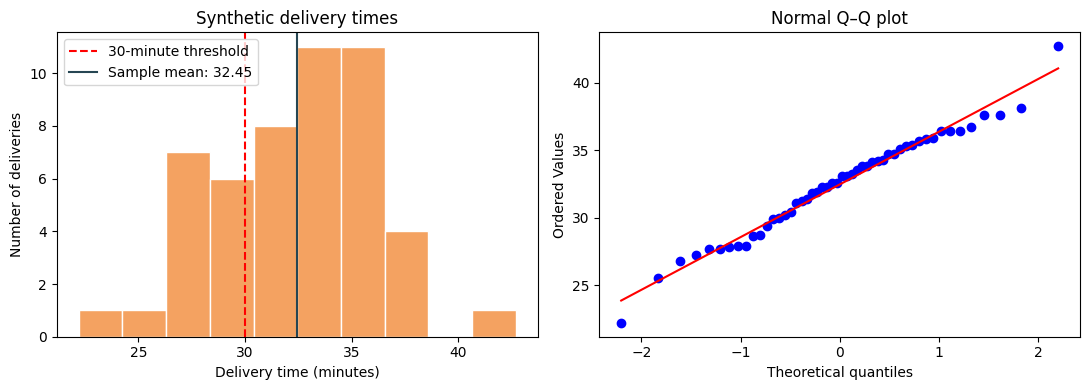

Shapiro–Wilk p-value: 0.7182
A large p-value does not establish normality.


In [4]:
fig, ax = plt.subplots(1,2,figsize=(11,4))
ax[0].hist(times,bins=10,color="#f4a261",edgecolor="white")
ax[0].axvline(30,color="red",linestyle="--",label="30-minute threshold")
ax[0].axvline(mean,color="#264653",label=f"Sample mean: {mean:.2f}")
ax[0].set(xlabel="Delivery time (minutes)",ylabel="Number of deliveries",title="Synthetic delivery times")
ax[0].legend()
stats.probplot(times,dist="norm",plot=ax[1])
ax[1].set_title("Normal Q–Q plot")
plt.tight_layout();plt.show()
normality = stats.shapiro(times)
print(f"Shapiro–Wilk p-value: {normality.pvalue:.4f}")
print("A large p-value does not establish normality.")


## 5. State hypotheses before testing
Let $\mu$ denote the population mean delivery time.

- **Null hypothesis:** $H_0: \mu \leq 30$ minutes.
- **Alternative hypothesis:** $H_1: \mu > 30$ minutes.
- **Significance level:** $\alpha=0.05$.

This is a **right-tailed one-sample t-test**. SciPy computes the test at the boundary of the null, $\mu_0=30$.

$$t=\frac{\bar{x}-30}{s/\sqrt{n}},\qquad df=n-1$$

The p-value is the probability, at the null boundary under the test assumptions, of a t-statistic at least as large as the one observed. It is not the probability that the shop's claim is true.

In [5]:
claimed_mean = 30.0
alpha = 0.05
t_stat_manual = (mean-claimed_mean)/se
result = stats.ttest_1samp(times,popmean=claimed_mean,alternative="greater")
assert np.isclose(t_stat_manual,result.statistic)
print(f"t-statistic: {result.statistic:.4f}")
print(f"Degrees of freedom: {n-1}")
print(f"One-sided p-value: {result.pvalue:.6f}")
reject = result.pvalue < alpha
print("Decision:","Reject H0" if reject else "Do not reject H0")


t-statistic: 4.5137
Degrees of freedom: 49
One-sided p-value: 0.000020
Decision: Reject H0


## 6. Confidence intervals and practical significance
The two-sided 95% interval summarizes uncertainty in the mean. The one-sided 95% lower bound corresponds directly to the right-tailed test: a lower bound above 30 rejects the null at 5%. These intervals concern the **population mean**, not individual delivery times. The mean excess and observed late-delivery percentage provide practical context.

In [6]:
ci_low, ci_high = stats.t.interval(0.95,df=n-1,loc=mean,scale=se)
lower_bound = mean-stats.t.ppf(0.95,df=n-1)*se
print(f"Two-sided 95% confidence interval: [{ci_low:.2f}, {ci_high:.2f}] minutes")
print(f"One-sided 95% interval: [{lower_bound:.2f}, infinity) minutes")
print(f"Mean excess above 30: {mean-30:.2f} minutes")
print(f"Late deliveries: {n-on_time}/{n} ({100*(n-on_time)/n:.1f}%)")


Two-sided 95% confidence interval: [31.36, 33.55] minutes
One-sided 95% interval: [31.54, infinity) minutes
Mean excess above 30: 2.45 minutes
Late deliveries: 36/50 (72.0%)


## 7. Automatically generated project conclusion

In [7]:
conclusion = ("There is statistically significant evidence that the population mean delivery time exceeds 30 minutes."
              if reject else "There is insufficient evidence that the population mean exceeds 30 minutes. This does not prove that the mean is at most 30.")
display(Markdown(f"""### Results for the synthetic example
- **Sample:** {n} deliveries.
- **Mean:** {mean:.2f} minutes; **sample standard deviation:** {sd:.2f} minutes.
- **Test:** t({n-1}) = {result.statistic:.3f}, one-sided p = {result.pvalue:.6f}.
- **Conclusion:** {conclusion}
- **Observed on-time rate:** {100*on_time/n:.1f}% ({on_time}/{n}).

**No finding about an actual pizza shop is justified:** these data are simulated. A mean test also does not establish that every delivery meets the promise.
"""))


### Results for the synthetic example
- **Sample:** 50 deliveries.
- **Mean:** 32.45 minutes; **sample standard deviation:** 3.84 minutes.
- **Test:** t(49) = 4.514, one-sided p = 0.000020.
- **Conclusion:** There is statistically significant evidence that the population mean delivery time exceeds 30 minutes.
- **Observed on-time rate:** 28.0% (14/50).

**No finding about an actual pizza shop is justified:** these data are simulated. A mean test also does not establish that every delivery meets the promise.


## 8. How to turn this into a real project
1. Define when the delivery clock starts and ends before collecting data.
2. Randomly sample deliveries over multiple days and time periods; avoid selecting only convenient or successful orders.
3. Record `delivery_id`, `delivery_minutes`, and optionally day, shift, driver, and distance. Do not record customer personal information.
4. Replace the simulation cell with your CSV import and run the notebook from the beginning.
5. Report descriptive statistics, assumptions, the prespecified test, effect size in minutes, and confidence intervals.
6. If the business goal is “at least 90% on time,” use a proportion-based analysis instead of a mean t-test. If the promise is literally “every delivery within 30 minutes,” any observed late delivery contradicts it for the sample; a finite sample cannot prove universal future compliance.

**Business suggestions, not tested causal findings:** investigate staffing during peak periods, travel distance, preparation delays, and driver allocation. Collect data before and after any change and design a separate comparison study.

## References
- SciPy one-sample t-test: https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.ttest_1samp.html
- SciPy Shapiro–Wilk test: https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.shapiro.html
- Data provenance: synthetic NumPy normal sample, seed 42, generated in this notebook.
